In [16]:
import torch
from torch import nn, einsum
from torch.nn import Module, ModuleList
import torch.nn.functional as F

from einops import rearrange, repeat

from hyper_connections import HyperConnections

# helpers

def exists(val):
    return val is not None

def default(val, d):
    return val if exists(val) else d

# classes

class PreNorm(Module):
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn = fn

    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)

# attention

class GEGLU(Module):
    def forward(self, x):
        x, gates = x.chunk(2, dim = -1)
        return x * F.gelu(gates)

class FeedForward(Module):
    def __init__(self, dim, mult = 4, dropout = 0.):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim * mult * 2),
            GEGLU(),
            nn.Dropout(dropout),
            nn.Linear(dim * mult, dim)
        )

    def forward(self, x, **kwargs):
        return self.net(x)

class Attention(Module):
    def __init__(
        self,
        dim,
        heads = 8,
        dim_head = 16,
        dropout = 0.
    ):
        super().__init__()
        inner_dim = dim_head * heads
        self.heads = heads
        self.scale = dim_head ** -0.5

        self.to_qkv = nn.Linear(dim, inner_dim * 3, bias = False)
        self.to_out = nn.Linear(inner_dim, dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h = self.heads
        q, k, v = self.to_qkv(x).chunk(3, dim = -1)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h = h), (q, k, v))
        sim = einsum('b h i d, b h j d -> b h i j', q, k) * self.scale

        attn = sim.softmax(dim = -1)
        dropped_attn = self.dropout(attn)

        out = einsum('b h i j, b h j d -> b h i d', dropped_attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)', h = h)
        return self.to_out(out), attn

# transformer

class Transformer(Module):
    def __init__(
        self,
        dim,
        depth,
        heads,
        dim_head,
        attn_dropout,
        ff_dropout,
        num_residual_streams = 4
    ):
        super().__init__()
        self.layers = ModuleList([])

        init_hyper_conn, self.expand_streams, self.reduce_streams = HyperConnections.get_init_and_expand_reduce_stream_functions(num_residual_streams, disable = num_residual_streams == 1)

        for _ in range(depth):
            self.layers.append(ModuleList([
                init_hyper_conn(dim = dim, branch = PreNorm(dim, Attention(dim, heads = heads, dim_head = dim_head, dropout = attn_dropout))),
                init_hyper_conn(dim = dim, branch = PreNorm(dim, FeedForward(dim, dropout = ff_dropout))),
            ]))

    def forward(self, x, return_attn = False):
        post_softmax_attns = []

        x = self.expand_streams(x)

        for attn, ff in self.layers:
            x, post_softmax_attn = attn(x)
            post_softmax_attns.append(post_softmax_attn)

            x = ff(x)

        x = self.reduce_streams(x)

        if not return_attn:
            return x

        return x, torch.stack(post_softmax_attns)
# mlp

class MLP(Module):
    def __init__(self, dims, act = None):
        super().__init__()
        dims_pairs = list(zip(dims[:-1], dims[1:]))
        layers = []
        for ind, (dim_in, dim_out) in enumerate(dims_pairs):
            is_last = ind >= (len(dims_pairs) - 1)
            linear = nn.Linear(dim_in, dim_out)
            layers.append(linear)

            if is_last:
                continue

            act = default(act, nn.ReLU())
            layers.append(act)

        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)

# main class

class ContTransformer(Module):
    def __init__(
        self,
        *,
        #categories,
        num_continuous,
        #dim,
        depth,
        heads,
        dim_head = 16,
        dim_out = 1,
        mlp_hidden_mults = (4, 2),
        mlp_act = None,
        num_special_tokens = 2,
        continuous_mean_std = None,
        attn_dropout = 0.,
        ff_dropout = 0.,
        use_shared_categ_embed = True,
        shared_categ_dim_divisor = 8.,   # in paper, they reserve dimension / 8 for category shared embedding
        num_residual_streams = 4
    ):
        super().__init__()
        assert num_continuous > 0, 'input shape must not be null'
        self.input_dim = num_continuous
        self.chunk_size = 16
        assert self.input_dim % self.chunk_size == 0
        self.num_chunks = self.input_dim // self.chunk_size
        self.d_model = self.chunk_size

        if exists(continuous_mean_std):
            assert continuous_mean_std.shape == (num_continuous, 2)
            self.register_buffer('continuous_mean_std', continuous_mean_std)
            self.norm = nn.LayerNorm(num_continuous)
        
        #positional embedddings
        self.pos_emb = nn.Parameter(torch.randn(1, self.num_chunks, self.d_model))

        # transformer on chunks 
        self.transformer = Transformer(
            dim = self.d_model,
            depth = depth,
            heads = heads,
            dim_head = dim_head,
            attn_dropout = attn_dropout,
            ff_dropout = ff_dropout,
            num_residual_streams = num_residual_streams
        )

        inp = self.num_chunks * self.d_model
        hidden_dims = [inp * mul for mul in mlp_hidden_mults]
        self.mlp = MLP([inp, *hidden_dims, dim_out], act=mlp_act)

    def forward(self, _x_categ, x_cont, return_attn = False):
        B = x_cont.size(0)
        assert x_cont.shape[1] == self.input_dim

        if exists(getattr(self, 'continuous_mean_std', None)):
            mean, std = self.continuous_mean_std.unbind(dim = -1)
            x_cont = (x_cont - mean) / std 

        x = x_cont.view(B, self.num_chunks, self.chunk_size)
        x = x + self.pos_emb
        out = self.transformer(x, return_attn=return_attn)
        x = out[0] if return_attn else out
        x = rearrange(x, 'b n d -> b (n d)')
        logits = self.mlp(x)

        return (logits, out[1]) if return_attn else logits

## utilize the same training loop 

### read in data

In [ ]:
model = ContTransformer(num_continuous=128, depth=2, heads=4)
x_cont = torch.randn(32, 128)  # batch of 32 proteins
logits = model(None, x_cont)   # returns (32, 1)

In [6]:
import pandas as pd

In [7]:
embeddings = "demo/all_n2vplus.emb"

with open(embeddings, 'r') as f:
    first_line = f.readline()
    num_nodes, emb_dim = map(int, first_line.strip().split())

df_emb = pd.read_csv(embeddings, skiprows=1, sep = ' ', header = None)

df_emb.rename(columns={0:'node_id'}, inplace=True)

embedding_cols = [f'emb{i}' for i in range(emb_dim)]
df_emb.solumns = ['node_id'] + embedding_cols

df_emb

/var/folders/ps/w4c6pfcn4hn1n6vbjpq6794w0000gp/T/ipykernel_54367/4235987244.py:12: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df_emb.solumns = ['node_id'] + embedding_cols


,node_id,1,2,3,4,5,6,7,8,9,...,119,120,121,122,123,124,125,126,127,128
0,229239,-0.016200,0.005921,0.073419,0.036151,-0.071059,-0.035445,-0.066091,-0.227935,-0.096804,...,0.092027,-0.058864,-0.100250,0.065719,0.123459,0.034667,-0.013363,-0.020001,0.218927,0.209972
1,349960,-0.027514,-0.080078,-0.036934,0.067515,-0.018240,-0.016869,-0.069665,-0.230616,-0.085825,...,0.116182,0.091114,-0.113546,0.100821,0.117250,0.051703,0.012014,0.071052,0.210882,0.211143
2,451828,-0.071351,-0.108720,0.034810,0.150857,0.054920,0.034807,-0.018754,-0.209027,0.020554,...,0.182601,0.076805,-0.107368,0.046390,0.077883,0.035370,-0.045838,-0.046140,0.195715,0.181764
3,298910,0.015234,-0.006220,-0.078138,-0.055389,0.030448,-0.147924,-0.087999,-0.226905,0.048794,...,0.036949,0.095145,-0.094461,0.114426,-0.065201,0.019495,-0.056148,-0.106633,0.222125,-0.018498
4,269305,-0.186198,-0.057258,0.051238,0.042863,-0.033990,-0.022146,-0.098589,-0.231825,-0.086538,...,0.191546,0.141000,-0.110096,0.156406,0.007403,0.052413,-0.039759,-0.019449,0.215584,0.110241
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19380,296847,-0.023395,0.007989,-0.017585,-0.065283,-0.023501,-0.072326,-0.025136,-0.147224,-0.088445,...,0.077080,0.024166,-0.084837,0.148708,0.078794,0.010558,-0.038134,-0.042341,0.149819,0.102454
19381,485051,-0.035958,-0.014783,-0.018900,-0.054081,-0.015117,-0.079302,-0.040744,-0.152468,-0.085778,...,0.072487,0.035039,-0.074505,0.171013,0.065142,0.007406,-0.043035,-0.056032,0.144909,0.112644
19382,303234,-0.037598,-0.007079,-0.016183,-0.072046,-0.038592,-0.076570,-0.037133,-0.135817,-0.071843,...,0.056538,0.022857,-0.071420,0.151335,0.063173,0.000718,-0.035855,-0.059651,0.141106,0.103220
19383,358542,-0.026331,-0.002575,0.002062,-0.025596,-0.022679,-0.063513,-0.006885,-0.163545,-0.081539,...,0.071941,0.015422,-0.081423,0.157130,0.076932,0.010787,-0.058393,-0.050583,0.163789,0.116368


In [8]:
f = open('/Users/eshav/Downloads/bioDBnet_db2db_250707135915_1812803228.txt', 'r')
lines = f.readlines()

ensembl_items = list()
for line in lines[1:]:
    items = line.split('\t')[1]
    if items == '-': continue
    items = items.split(';')
    for item in items:
        item = item.strip()
        try:
            if item != '': ensembl_items.append(int(item.replace('ENSP','')))
        except:
            pass

len(ensembl_items)

4311

In [9]:
import numpy as np
import random
random.seed(42)

vectors = list()
ids = list()
labels = list()

f = open("demo/all_n2vplus.emb", 'r')
lines = f.readlines()

X = []
y = []
proteins_to_emb = []


for line in lines[1:]:
    line = list(map(float, line.split()))
    key = int(line[0])
    value = np.array(line[1:])
    
    vectors.append(value)
    ids.append(key)
    labels.append(0)
    
    if key in ensembl_items:
        labels[-1] = 1
        X.append(value)
        y.append(1)
        proteins_to_emb.append(key)
    else:
        if random.random() > 0.9:
            X.append(value)
            y.append(0)
            proteins_to_emb.append(key)
vectors = np.array(vectors)
X = np.array(X)

In [10]:
key2val = {i:v for i, v in zip(ids, vectors)}

In [11]:
f = open('/Users/eshav/Downloads/bioDBnet_db2db_250707135915_1812803228.txt', 'r')
lines = f.readlines()

n = 0

ensembl_items = list()
for line in lines[1:]:
    items = line.split('\t')[1]
    if items == '-': continue
    items = items.split(';')
    
    for item in items:
        item = item.strip()
        try:
            if item != '':
                if int(item.replace('ENSP','')) in ids:
                       n += 1
                       break
        except:
            pass

print(n)

601


In [12]:
import pandas as pd
df = pd.DataFrame(X)
df['target'] = y
df

,0,1,2,3,4,5,6,7,8,9,...,119,120,121,122,123,124,125,126,127,target
0,-0.071351,-0.108720,0.034810,0.150857,0.054920,0.034807,-0.018754,-0.209027,0.020554,-0.154530,...,0.076805,-0.107368,0.046390,0.077883,0.035370,-0.045838,-0.046140,0.195715,0.181764,1
1,0.038651,-0.017476,0.052701,0.071277,0.014295,-0.158209,-0.049758,-0.114217,-0.226067,-0.111746,...,0.058139,-0.179301,0.077051,0.098540,0.085674,0.062816,0.011521,0.223031,0.226825,1
2,-0.077355,-0.047118,-0.050669,0.057968,-0.087158,0.041584,0.037871,-0.192774,-0.132135,-0.073415,...,0.084698,-0.090835,0.194844,0.120005,0.036501,0.019904,-0.113406,0.325233,0.170783,1
3,-0.007166,-0.154761,0.013473,0.160234,0.054655,-0.238443,-0.055751,-0.151960,-0.110707,-0.179474,...,0.174864,-0.211960,0.172678,0.170753,0.102318,0.021428,0.021918,0.247352,0.175978,1
4,-0.069395,-0.056747,0.016273,0.061387,-0.080987,-0.101352,-0.096733,-0.230205,0.075670,-0.135979,...,-0.000274,-0.107589,0.138324,0.125535,0.030488,0.110164,0.046268,0.306246,0.060327,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2480,-0.004532,-0.017612,-0.010215,-0.048133,0.027408,-0.093663,-0.023460,-0.179353,-0.130757,-0.064173,...,0.044696,-0.097239,0.175149,0.084364,-0.000418,-0.065761,-0.083872,0.175156,0.135987,0
2481,-0.024833,-0.012721,-0.010489,-0.063792,-0.037726,-0.088465,-0.037095,-0.162964,-0.081691,-0.042740,...,0.014041,-0.077851,0.182687,0.095439,0.006484,-0.032868,-0.042720,0.193313,0.108725,0
2482,-0.032563,0.003700,-0.011998,-0.059191,-0.027288,-0.075701,-0.042868,-0.168035,-0.079817,-0.041785,...,0.009477,-0.075682,0.172720,0.083884,0.003583,-0.032967,-0.062465,0.165859,0.110948,0
2483,-0.053250,-0.021628,0.005761,-0.054385,-0.033163,-0.077569,-0.032175,-0.194938,-0.064691,-0.010334,...,-0.011759,-0.055349,0.154603,0.067859,0.018905,-0.064310,-0.052050,0.177940,0.127326,0


In [23]:
import torch 

embeddings = []

with open('alln2vplus.emb', 'r') as f:
    next(f)
    for line in f:
        parts = line.strip().split()
        vector = [float(x) for x in parts[1:]]
        tensor = torch.tensor(vector)
        embeddings.append(tensor)

In [24]:
embedding_matrix = torch.stack(embeddings)

In [25]:
embedding_matrix

tensor([[-0.0162,  0.0059,  0.0734,  ..., -0.0200,  0.2189,  0.2100],
        [-0.0275, -0.0801, -0.0369,  ...,  0.0711,  0.2109,  0.2111],
        [-0.0714, -0.1087,  0.0348,  ..., -0.0461,  0.1957,  0.1818],
        ...,
        [-0.0376, -0.0071, -0.0162,  ..., -0.0597,  0.1411,  0.1032],
        [-0.0263, -0.0026,  0.0021,  ..., -0.0506,  0.1638,  0.1164],
        [-0.0196, -0.0047, -0.0043,  ..., -0.0646,  0.1364,  0.1053]])

In [26]:
x_cont = torch.tensor(embedding_matrix).to(torch.float32).to(device)

/var/folders/ps/w4c6pfcn4hn1n6vbjpq6794w0000gp/T/ipykernel_54367/494888646.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_cont = torch.tensor(embedding_matrix).to(torch.float32).to(device)


In [27]:
with torch.no_grad():
    pred = model(None, x_cont)

In [18]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [29]:
import torch
import torch.nn as nn
#from tab_transformer_pytorch import TabTransformer

cont_mean_std = None

model = ContTransformer(
    num_continuous = 128,                # number of continuous values
    depth = 6,                          # depth, paper recommended 6
    heads = 8,                          # heads, paper recommends 8
    dim_head = 16,
    attn_dropout = 0.1,                 # post-attention dropout
    ff_dropout = 0.1,                   # feed forward dropout
    mlp_hidden_mults = (4, 2),          # relative multiples of each hidden dimension of the last mlp to logits
    mlp_act = nn.ReLU(),                # activation for final mlp, defaults to relu, but could be anything else (selu etc)
    dim_out = 1,
    continuous_mean_std = cont_mean_std # (optional) - normalize the continuous values before layer norm
)

model = model.to(device)
model.eval()

with torch.no_grad():
    pred = model(None, x_cont)
print(pred.shape)
print(pred[0].item())

torch.Size([19385, 1])
0.1208757758140564


### training loop

In [30]:
import torch 
import torch.nn as nn
import torch.optim as optim 
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np

In [31]:
# want a 3:1 split 
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size = 0.3, stratify = df['target'], random_state=123)

In [32]:
# need to create a custom dataset in order to meet the requirements of pytorch
class PPInet(Dataset):
    def __init__(self, train_df):
        #need numpy array with just the embeddings 
        self.X = train_df.drop(columns = ['target']).values.astype(np.float32)
        self.y = train_df['target'].values.astype(np.float32)
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return torch.tensor(self.X[idx]), torch.tensor(self.y[idx])
    #def __getitem__(self, idx):
        #return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor([self.y[idx]], dtype=torch.float32)


In [52]:
for X_batch, y_batch in loader:
    print(X_batch)

tensor([[-0.0341,  0.0045,  0.0052,  ..., -0.1197,  0.1415,  0.1124],
        [-0.2198, -0.0162,  0.0301,  ..., -0.0634,  0.2913,  0.2733],
        [ 0.0104,  0.1998,  0.1252,  ..., -0.0470,  0.1642,  0.1069],
        ...,
        [-0.0697,  0.1225,  0.0231,  ..., -0.0347,  0.1726,  0.1032],
        [ 0.0579, -0.1193,  0.0473,  ..., -0.0564,  0.2028,  0.1208],
        [-0.0943,  0.1788,  0.0949,  ..., -0.0501,  0.1484,  0.1054]])
tensor([[ 0.0226,  0.0200,  0.0668,  ...,  0.1339, -0.0201,  0.2386],
        [ 0.0330, -0.1064, -0.0024,  ..., -0.0687,  0.2388,  0.0703],
        [ 0.1096, -0.1297,  0.0558,  ..., -0.0967,  0.2567,  0.0617],
        ...,
        [-0.1048,  0.0226,  0.0322,  ..., -0.0505,  0.2632,  0.2571],
        [-0.1441, -0.0324,  0.0796,  ..., -0.0549,  0.3358,  0.3436],
        [-0.0703,  0.1010,  0.1335,  ..., -0.0100,  0.1422,  0.1674]])
tensor([[-0.0857, -0.1105, -0.1068,  ..., -0.0933,  0.2840, -0.0263],
        [-0.0326, -0.0672, -0.1378,  ..., -0.0745,  0.0935,  0

In [35]:
dataset = PPInet(train_df)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 40
epoch_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device).float()
        #y_batch = y_batch.float()
        y_batch = y_batch.float().view(-1, 1)

        categorical = torch.empty((X_batch.size(0), 0), dtype=torch.long).to(device)

        preds = model(None, X_batch)
        batch_loss = criterion(preds, y_batch)

        optimizer.zero_grad()
        batch_loss.backward()
        optimizer.step()

        total_loss += batch_loss.item()

    avg_loss = total_loss / len(loader)
    epoch_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

Epoch 1/40, Loss: 0.4373
Epoch 2/40, Loss: 0.3500
Epoch 3/40, Loss: 0.3409
Epoch 4/40, Loss: 0.3364
Epoch 5/40, Loss: 0.3338
Epoch 6/40, Loss: 0.3189
Epoch 7/40, Loss: 0.3096
Epoch 8/40, Loss: 0.3170
Epoch 9/40, Loss: 0.3289
Epoch 10/40, Loss: 0.3117
Epoch 11/40, Loss: 0.3208
Epoch 12/40, Loss: 0.3327
Epoch 13/40, Loss: 0.3122
Epoch 14/40, Loss: 0.3100
Epoch 15/40, Loss: 0.3211
Epoch 16/40, Loss: 0.3131
Epoch 17/40, Loss: 0.3102
Epoch 18/40, Loss: 0.3138
Epoch 19/40, Loss: 0.3098
Epoch 20/40, Loss: 0.3035
Epoch 21/40, Loss: 0.3015
Epoch 22/40, Loss: 0.3056
Epoch 23/40, Loss: 0.3027
Epoch 24/40, Loss: 0.3222
Epoch 25/40, Loss: 0.3195
Epoch 26/40, Loss: 0.3127
Epoch 27/40, Loss: 0.3187
Epoch 28/40, Loss: 0.3067
Epoch 29/40, Loss: 0.3011
Epoch 30/40, Loss: 0.3044
Epoch 31/40, Loss: 0.3188
Epoch 32/40, Loss: 0.3010
Epoch 33/40, Loss: 0.3151
Epoch 34/40, Loss: 0.3081
Epoch 35/40, Loss: 0.3108
Epoch 36/40, Loss: 0.2955
Epoch 37/40, Loss: 0.2968
Epoch 38/40, Loss: 0.2970
Epoch 39/40, Loss: 0.

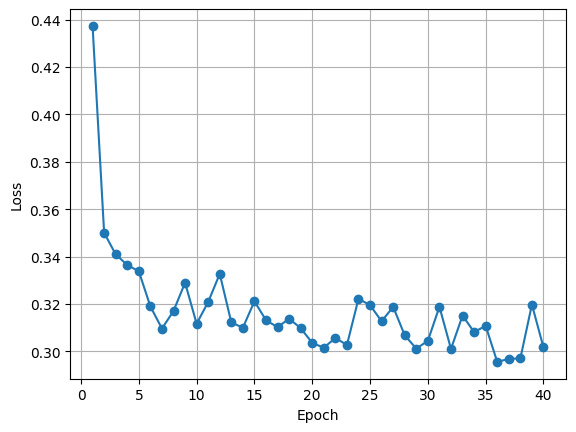

In [36]:
import matplotlib.pyplot as plt 

plt.plot(range(1, epochs+1), epoch_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

In [38]:
test_df

,0,1,2,3,4,5,6,7,8,9,...,119,120,121,122,123,124,125,126,127,target
1645,-0.002190,-0.091421,-0.021771,0.287747,-0.100240,-0.107434,-0.010478,-0.122088,-0.031434,-0.342904,...,0.186581,-0.023374,0.208998,0.112096,0.054291,-0.029060,-0.033610,0.255924,0.114499,0
366,-0.037490,-0.040025,0.024823,-0.024960,0.087038,-0.019333,-0.179136,-0.122159,-0.010997,-0.163338,...,0.000627,-0.193540,0.146635,0.081324,0.014926,0.079760,-0.075912,0.281408,0.117449,1
2051,-0.016966,0.021145,0.035238,-0.183105,0.056380,-0.271293,0.209414,-0.097306,-0.124300,0.071593,...,0.114164,-0.210950,0.393197,0.085814,-0.076096,-0.184963,-0.094301,0.234979,0.064607,0
593,0.021748,-0.089315,-0.048191,0.176593,0.004141,0.076876,-0.156794,-0.192974,0.158255,-0.202192,...,0.192827,-0.027204,0.007674,0.028001,0.061700,-0.005441,0.017783,0.126145,0.037714,0
1651,0.064085,-0.020057,0.028880,-0.040732,0.213733,-0.069266,-0.028576,-0.187713,-0.221358,0.018319,...,0.076125,-0.157385,0.140281,0.129071,0.123095,-0.116837,-0.108741,0.110825,0.164219,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,0.048130,0.041134,0.203490,-0.053931,-0.034368,-0.283739,-0.039551,-0.178179,-0.324360,-0.050626,...,-0.053524,-0.129004,0.061560,0.048004,0.034640,0.006650,-0.053269,0.230171,0.260923,0
2129,0.076762,0.031766,0.013285,0.213340,-0.115739,-0.164670,0.119994,-0.117821,-0.213798,-0.335417,...,0.285746,-0.049802,0.207185,0.104725,0.012438,-0.146998,-0.085698,0.135693,0.064581,0
51,-0.035764,-0.138350,-0.015432,0.201826,0.066651,0.035354,-0.072033,-0.154795,-0.118410,-0.136304,...,0.048397,-0.123398,0.146397,0.201158,0.137591,0.113856,-0.025169,0.235026,0.153133,1
2110,-0.020593,-0.089901,-0.187294,-0.045233,0.025287,-0.041534,-0.038083,-0.288881,-0.086315,-0.136788,...,-0.089995,-0.101161,0.264925,0.018153,-0.087118,0.081904,-0.138214,0.204747,0.121725,0


In [39]:
test_dataset = PPInet(test_df)
test_loader = DataLoader(dataset, batch_size=128, shuffle=True)

In [50]:
test_df

,0,1,2,3,4,5,6,7,8,9,...,119,120,121,122,123,124,125,126,127,target
1645,-0.002190,-0.091421,-0.021771,0.287747,-0.100240,-0.107434,-0.010478,-0.122088,-0.031434,-0.342904,...,0.186581,-0.023374,0.208998,0.112096,0.054291,-0.029060,-0.033610,0.255924,0.114499,0
366,-0.037490,-0.040025,0.024823,-0.024960,0.087038,-0.019333,-0.179136,-0.122159,-0.010997,-0.163338,...,0.000627,-0.193540,0.146635,0.081324,0.014926,0.079760,-0.075912,0.281408,0.117449,1
2051,-0.016966,0.021145,0.035238,-0.183105,0.056380,-0.271293,0.209414,-0.097306,-0.124300,0.071593,...,0.114164,-0.210950,0.393197,0.085814,-0.076096,-0.184963,-0.094301,0.234979,0.064607,0
593,0.021748,-0.089315,-0.048191,0.176593,0.004141,0.076876,-0.156794,-0.192974,0.158255,-0.202192,...,0.192827,-0.027204,0.007674,0.028001,0.061700,-0.005441,0.017783,0.126145,0.037714,0
1651,0.064085,-0.020057,0.028880,-0.040732,0.213733,-0.069266,-0.028576,-0.187713,-0.221358,0.018319,...,0.076125,-0.157385,0.140281,0.129071,0.123095,-0.116837,-0.108741,0.110825,0.164219,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,0.048130,0.041134,0.203490,-0.053931,-0.034368,-0.283739,-0.039551,-0.178179,-0.324360,-0.050626,...,-0.053524,-0.129004,0.061560,0.048004,0.034640,0.006650,-0.053269,0.230171,0.260923,0
2129,0.076762,0.031766,0.013285,0.213340,-0.115739,-0.164670,0.119994,-0.117821,-0.213798,-0.335417,...,0.285746,-0.049802,0.207185,0.104725,0.012438,-0.146998,-0.085698,0.135693,0.064581,0
51,-0.035764,-0.138350,-0.015432,0.201826,0.066651,0.035354,-0.072033,-0.154795,-0.118410,-0.136304,...,0.048397,-0.123398,0.146397,0.201158,0.137591,0.113856,-0.025169,0.235026,0.153133,1
2110,-0.020593,-0.089901,-0.187294,-0.045233,0.025287,-0.041534,-0.038083,-0.288881,-0.086315,-0.136788,...,-0.089995,-0.101161,0.264925,0.018153,-0.087118,0.081904,-0.138214,0.204747,0.121725,0


In [40]:
model.eval()
test_loss = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        #X_batch - input features, y_batch - output features
        y_batch = y_batch.unsqueeze(1)
        categorical = torch.empty((X_batch.size(0), 0), dtype=torch.long)

        preds = model(categorical, X_batch) #output prediction PER BATCH 
        loss = criterion(preds, y_batch) #converts logits to probabilities and applys BCEloss
        test_loss += loss.item()

        all_preds.append(torch.sigmoid(preds)) # OUTPUT
        all_labels.append(y_batch) #TRUE values

# Combine all batches
all_preds = torch.cat(all_preds).numpy() #each indiviual tensor into big one 
all_labels = torch.cat(all_labels).numpy()

# Average test loss
avg_test_loss = test_loss / len(test_loader)
print(f"Test Loss: {avg_test_loss:.4f}")

Test Loss: 0.2773


In [41]:
# need to make the outputs a single tensor of one dimension 
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(categorical, X_batch)
        probs = torch.sigmoid(outputs)

        all_preds.extend(probs.squeeze().numpy())
        all_labels.extend(y_batch.numpy())

In [42]:
all_labels = np.array(all_labels).astype(int)  # now array of 0s and 1s
all_labels

array([0, 1, 0, ..., 0, 0, 0])

In [43]:
all_preds = np.array(all_preds)
binary_preds = (all_preds >= 0.5).astype(int)
binary_preds

array([0, 1, 1, ..., 0, 1, 0])

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc

In [1]:
precision = precision_score(all_labels, binary_preds)
recall = recall_score(all_labels, binary_preds)
f1 = f1_score(all_labels, binary_preds)

print("precision" + precision)
print("recall" + recall)
print("f1" + f1)

NameError: name 'precision_score' is not defined

ROC AUC: 0.9385


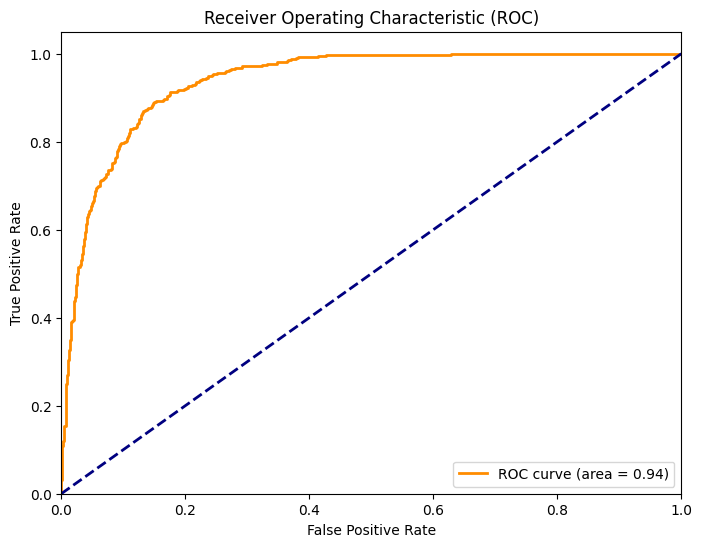

Precision-Recall AUC: 0.8152


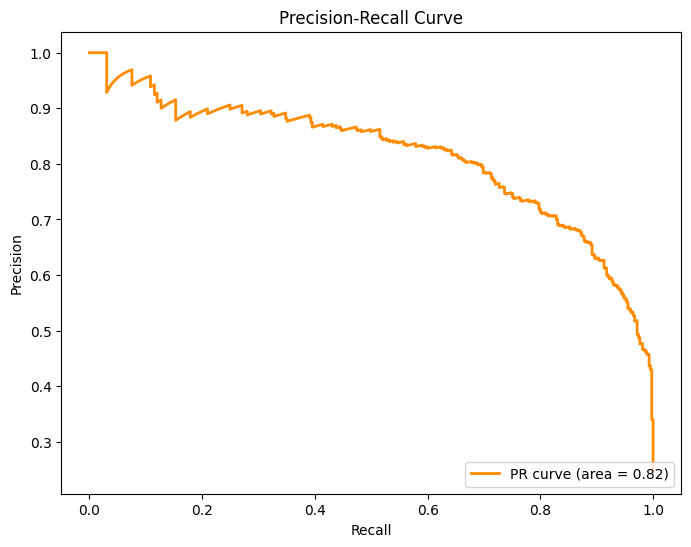

In [47]:
# Calculate ROC AUC
roc_auc = roc_auc_score(all_labels, all_preds)
print(f"ROC AUC: {roc_auc:.4f}")

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(all_labels, all_preds)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

# Calculate and print Precision-Recall AUC
from sklearn.metrics import precision_recall_curve, auc
precision, recall, _ = precision_recall_curve(all_labels, all_preds)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC: {pr_auc:.4f}")

# Plot Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='darkorange', lw=2, label=f'PR curve (area = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower right")
plt.show()